# 03 — Baselines and linear regression

**Goal of this notebook:** find out how much of a phone's (log) price its listed specs explain, and how much extra each brand charges for the same specs, using ordinary linear regression.

Everything here uses the **training set only** (558 phones). Models are compared by **5-fold grouped cross-validation**: the training set is cut into 5 parts (all storage variants of a phone in the same part). Each part takes one turn as the validation set while the model is fitted on the other 4, and we report the mean ± standard deviation of the 5 scores. The test set stays locked until Phase 7.

**Metrics** (same for every model in the project):
- **R² on log price**: the share of the variation in log price that the model explains. 1 is perfect; 0 is no better than always predicting the average.
- **Median % error**: we turn the prediction back into rupees (`exp(prediction)`) and take the median of |predicted − actual| / actual. "Median" means half of the phones are predicted better than this.
- **MAE (₹)**: mean absolute error in rupees. It is dominated by expensive phones, where errors are large in rupees.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

from features import NUMERIC_FEATURES
from split import load_train_test, cv_folds

pd.set_option("display.width", 200)

train, test = load_train_test(include_web_lookup=True)       # main version (702 phones)
train_name, _ = load_train_test(include_web_lookup=False)    # robustness version (695 phones)
print("training phones:", len(train), "| name-only training phones:", len(train_name))
del test   # not used in this notebook

training phones: 558 | name-only training phones: 555


## 0. Why grouped cross-validation? A quick check
Phase 3 explained that a random split of rows lets storage variants of the same phone sit on both sides. Here we measure what that would do to a score, using Model B (defined below) on the training set: once with random 5-fold CV, once with grouped 5-fold CV.

**Building blocks used in the whole notebook.** First the **design matrix** X: one row per phone, the 9 numeric features, plus one 0/1 **dummy column** per chip group and per brand (categories are explained in section 2).

In [2]:
# Reference categories: each category coefficient is "difference from this one"
REFERENCE_COLUMNS = ["chip_group_snapdragon_other", "brand_Samsung"]

def design_matrix(rows, categorical=("chip_group", "brand")):
    categorical = list(categorical)
    X = pd.get_dummies(rows[NUMERIC_FEATURES + categorical], columns=categorical, dtype=float)
    # The dummies of one category add up to 1 in every row, exactly like the intercept
    # column, so keeping all of them would duplicate the intercept: drop the reference.
    return X.drop(columns=[c for c in REFERENCE_COLUMNS if c in X.columns])

y = train["log_price"]
X_a = design_matrix(train, ["chip_group"])   # Model A: specs + chip
X_b = design_matrix(train)                   # Model B: specs + chip + brand
print("Model A design matrix:", X_a.shape, "| Model B design matrix:", X_b.shape)
X_b.head(3)

Model A design matrix: (558, 17) | Model B design matrix: (558, 31)


,log2_ram,log2_storage,battery_mah,screen_in,main_back_mp,front_mp,n_back_cameras,weight_g,year,chip_group_dimensity_high,...,brand_Motorola,brand_Nokia,brand_OnePlus,brand_Oppo,brand_Other,brand_POCO,brand_Realme,brand_Tecno,brand_Vivo,brand_Xiaomi
3,2.584963,7.0,4200.0,6.7,48.0,12.0,1,203.0,2024,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2.584963,8.0,4200.0,6.7,48.0,12.0,1,203.0,2024,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,2.584963,9.0,4200.0,6.7,48.0,12.0,1,203.0,2024,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Next the three metrics from the top of the notebook, and a helper that turns the 5 per-fold scores into "mean ± std".

In [3]:
def score(y_true_log, y_pred_log):
    y_true_log, y_pred_log = np.asarray(y_true_log), np.asarray(y_pred_log)
    # R² = 1 − RSS / TSS, on the log scale
    r2 = 1 - np.sum((y_true_log - y_pred_log) ** 2) / np.sum((y_true_log - y_true_log.mean()) ** 2)
    price_true, price_pred = np.exp(y_true_log), np.exp(y_pred_log)   # back to rupees
    return {"R²": r2,
            "median % error": 100 * np.median(np.abs(price_pred / price_true - 1)),
            "MAE (₹)": np.mean(np.abs(price_pred - price_true))}

def mean_pm_std(folds):
    fmt = {"R²": "{:.3f}", "median % error": "{:.1f}", "MAE (₹)": "{:,.0f}"}
    return {m: f.format(folds[m].mean()) + " ± " + f.format(folds[m].std()) for m, f in fmt.items()}

And the cross-validation loop. The 5 grouped folds were made once by `src/split.py` and saved in `split.csv` (column `fold`), so every notebook and every machine uses exactly the same folds; `cv_folds(rows)` returns them as (fitting positions, validation positions) pairs. `model` says what to fit on the 4 fitting folds: one of the two baselines (section 1), or OLS on the Model A or Model B design matrix. For OLS inside the loop we use sklearn's `LinearRegression`, which gives exactly the same coefficients as our own `fit_ols` in section 2 (checked there).

In [4]:
def cross_validate(rows, model, folds=None):
    if folds is None:
        folds = cv_folds(rows)   # the 5 grouped folds saved in split.csv
    scores = []
    for fold, (fit_idx, val_idx) in enumerate(folds):
        fit, val = rows.iloc[fit_idx], rows.iloc[val_idx]
        if model == "overall mean":
            pred = np.full(len(val), fit["log_price"].mean())
        elif model == "brand mean":   # a brand never seen while fitting gets the overall mean
            brand_means = fit.groupby("brand")["log_price"].mean()
            pred = val["brand"].map(brand_means).fillna(fit["log_price"].mean())
        else:                         # "A" or "B": OLS on the design matrix
            categorical = ["chip_group"] if model == "A" else ["chip_group", "brand"]
            X_fit = design_matrix(fit, categorical)
            # A category that never appeared while fitting has no column in X_fit, so reindex
            # drops it: its dummies are all 0, i.e. it behaves like the reference category.
            X_val = design_matrix(val, categorical).reindex(columns=X_fit.columns, fill_value=0)
            pred = LinearRegression().fit(X_fit, fit["log_price"]).predict(X_val)
        scores.append(score(val["log_price"], pred))
    return pd.DataFrame(scores)

In [5]:
random_folds = cross_validate(train, "B", list(KFold(5, shuffle=True, random_state=42).split(train)))
grouped_folds = cross_validate(train, "B")
pd.DataFrame({"Model B, random folds": mean_pm_std(random_folds),
              "Model B, grouped folds": mean_pm_std(grouped_folds)}).T

,R²,median % error,MAE (₹)
"Model B, random folds",0.855 ± 0.011,18.8 ± 1.9,"11,578 ± 1,820"
"Model B, grouped folds",0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"


**Takeaway:** random folds give R² 0.855 and grouped folds 0.845, so the optimistic bias from leaking storage variants is real but small here (about 1 R² point). Variants differ in storage, which is itself a big price driver, so a sibling in training does not simply give away the answer. The grouped scores also vary more between folds (± 0.018 vs ± 0.011), because each grouped fold contains genuinely new phones. We use grouped CV everywhere, because the question is how well we price **unseen** phones.

## 1. Baselines
A **baseline** is a deliberately simple prediction that any real model must beat. Without one, an R² of 0.8 has nothing to be compared against.
- **Baseline 1 — overall mean:** predict the training mean of log price for every phone. Its R² is about 0 by construction.
- **Baseline 2 — brand mean:** predict the mean log price of the phone's brand in the training folds. This shows how much brand *alone* tells us. A brand never seen while fitting gets the overall mean.

In [6]:
results = {}       # model name -> per-fold scores (main data)
results_name = {}  # same, name-only data
for name, model in [("Baseline 1: overall mean", "overall mean"), ("Baseline 2: brand mean", "brand mean")]:
    results[name] = cross_validate(train, model)
    results_name[name] = cross_validate(train_name, model)
pd.DataFrame({name: mean_pm_std(folds) for name, folds in results.items()}).T

,R²,median % error,MAE (₹)
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"


**Takeaway:** always predicting the average is off by a median of 59 % (R² ≈ 0). Knowing only the brand already explains 37 % of the variation in log price (median error 40 %). Every model below must clearly beat 0.37.

## 2. Model A — "hardware value": specs + chip family, no brand
**Ordinary least squares (OLS)** linear regression finds the coefficients *b* that minimise the sum of squared errors of

log_price = b₀ + b₁·log2_ram + b₂·log2_storage + … + (chip-family effects).

The chip enters through `chip_group`, which is `chip_family` with Apple A-series and Snapdragon 8 chips merged into one flagship group (the reason is shown in section 3). It is a **categorical** feature, so it enters as **dummy variables** (one 0/1 column per group). One group is left out as the **reference**, here `snapdragon_other`, the largest group. Each chip coefficient is then the difference from a Snapdragon-other phone with the same specs. Leaving one out is required: the dummies of all families always add up to 1, which would duplicate the intercept.

Model A has **no brand**. It answers "what would a typical phone with this hardware cost?", which we call the phone's *hardware value*.

We fit OLS ourselves with the **normal equations** (`fit_ols` below). Besides the coefficients, it gives a **95 % confidence interval** for every coefficient: the range of values compatible with the data. If we repeated the data collection many times, about 95 % of intervals built this way would contain the true value.

In [7]:
def fit_ols(X, y):
    X1 = np.column_stack([np.ones(len(X)), X])              # add the intercept column of 1s
    y = np.asarray(y, dtype=float)
    n, p = X1.shape                                          # n phones, p coefficients (incl. intercept)
    XtX_inv = np.linalg.inv(X1.T @ X1)                       # (XᵀX)⁻¹
    b = XtX_inv @ X1.T @ y                                   # b = (XᵀX)⁻¹ Xᵀy
    rss = np.sum((y - X1 @ b) ** 2)                          # RSS = Σ (yᵢ − ŷᵢ)²
    sigma2 = rss / (n - p)                                   # σ̂² = RSS / (n − p)
    se = np.sqrt(np.diag(sigma2 * XtX_inv))                  # se(bⱼ) = √( σ̂² [(XᵀX)⁻¹]ⱼⱼ )
    t_mult = stats.t.ppf(0.975, n - p)                       # 95 % CI: bⱼ ± t₀.₉₇₅,ₙ₋ₚ · se(bⱼ)
    p_value = 2 * (1 - stats.t.cdf(np.abs(b / se), n - p))   # t = bⱼ / se(bⱼ); p = 2·P(T > |t|)
    return pd.DataFrame({"coef": b, "CI low": b - t_mult * se, "CI high": b + t_mult * se,
                         "p-value": p_value}, index=["intercept"] + list(X.columns))

def predict_ols(table, X):
    return table.loc["intercept", "coef"] + X @ table["coef"].drop("intercept")

In [8]:
results["Model A: specs + chip"] = cross_validate(train, "A")
results_name["Model A: specs + chip"] = cross_validate(train_name, "A")

ols_a = fit_ols(X_a, y)
r2_a = score(y, predict_ols(ols_a, X_a))["R²"]

# Check once: sklearn's LinearRegression (used inside cross-validation) gives the same coefficients
sk = LinearRegression().fit(X_a, y)
diff = np.abs(np.r_[sk.intercept_, sk.coef_] - ols_a["coef"].to_numpy()).max()
print(f"largest difference fit_ols vs LinearRegression: {diff:.1e}  (equal to 6 decimals: {diff < 5e-7})")

largest difference fit_ols vs LinearRegression: 4.1e-08  (equal to 6 decimals: True)


In [9]:
# How to read each coefficient in plain words: the change in the feature we describe
UNIT = {"log2_ram": (1, "doubling RAM"), "log2_storage": (1, "doubling storage"),
        "battery_mah": (1000, "+1000 mAh battery"), "screen_in": (0.5, "+0.5 inch screen"),
        "main_back_mp": (10, "+10 MP main camera"), "front_mp": (10, "+10 MP front camera"),
        "n_back_cameras": (1, "+1 back camera"), "weight_g": (10, "+10 g weight"), "year": (1, "+1 year newer")}

def coef_table(ols):
    t = ols.drop("intercept")
    step = np.array([UNIT.get(term, (1, ""))[0] for term in t.index])
    return pd.DataFrame({
        "change": [UNIT.get(term, (1, "vs reference"))[1] for term in t.index],
        "coef (per change)": t["coef"] * step,
        "% price effect": 100 * (np.exp(t["coef"] * step) - 1),     # log target: % = exp(b) − 1
        "95% CI low %": 100 * (np.exp(t["CI low"] * step) - 1),
        "95% CI high %": 100 * (np.exp(t["CI high"] * step) - 1),
        "p-value": t["p-value"]})

table_a = coef_table(ols_a)
print(f"Model A fitted on {len(y)} training phones, in-sample R² = {r2_a:.3f}")
table_a.round(3)

Model A fitted on 558 training phones, in-sample R² = 0.799


,change,coef (per change),% price effect,95% CI low %,95% CI high %,p-value
log2_ram,doubling RAM,0.240,27.104,16.455,38.727,0.000
log2_storage,doubling storage,0.203,22.511,16.599,28.722,0.000
battery_mah,+1000 mAh battery,-0.375,-31.276,-35.855,-26.371,0.000
screen_in,+0.5 inch screen,-0.104,-9.850,-16.986,-2.100,0.014
main_back_mp,+10 MP main camera,-0.002,-0.236,-1.773,1.325,0.765
front_mp,+10 MP front camera,0.010,1.049,-2.538,4.769,0.571
n_back_cameras,+1 back camera,-0.008,-0.804,-4.766,3.322,0.697
weight_g,+10 g weight,0.113,11.969,8.886,15.139,0.000
year,+1 year newer,0.069,7.174,4.739,9.667,0.000
chip_group_dimensity_high,vs reference,0.226,25.417,10.050,42.930,0.001


**How to read the table.** Because the target is log price, a coefficient *b* is a **multiplicative** effect: the change multiplies the price by exp(*b*), i.e. changes it by (exp(*b*) − 1) × 100 %. For `log2_ram` one unit means *doubling* RAM, so "% price effect" is the price change for doubling RAM with every other spec (and the chip family) held fixed. For other numeric specs we show a more readable step (+1000 mAh, +10 MP, …), which simply multiplies *b* by that step. The **p-value** is the probability of seeing an estimate this far from zero if the true effect were zero. Small values (below 0.05) mean the data clearly shows an effect.

**Takeaway (Model A, hardware only).** Cross-validated R² is about 0.77 (table in section 3), so specs and chip alone explain most of the price variation. The in-sample R², 0.80 on the training data, is slightly higher, as fitted data always is. In plain words, with all other specs held fixed:
- **Doubling RAM** goes with **+27 %** price (95 % CI 16 % to 39 %), and **doubling storage** with **+23 %** (17 % to 29 %).
- **Chip group** matters a lot. A flagship chip (Snapdragon 8 or Apple A) adds **+84 %** over a mid-range Snapdragon, while budget chips cut price (Helio −34 %, Unisoc −45 %). Tensor (+75 %) and Kirin (+100 %) look valuable too, but those chips are used by only one brand each (Google, Huawei), so here they partly stand in for the brand.
- **Weight** +12 % per 10 g (premium materials, foldables) and **launch year** +7 % per year.
- **Camera megapixels** and the **number of back cameras** have no detectable effect (all p > 0.5, intervals include 0).
- **Battery** has a *negative* coefficient: −31 % per extra 1000 mAh. This is not "batteries make phones cheaper". Among phones with the *same* RAM, storage, chip, weight, screen and year, the ones with a bigger battery tend to be budget "battery champion" models, while flagships stay slim. A coefficient describes an association **holding the other features fixed**, not a cause.
- **Screen size** is slightly negative here (−10 % per 0.5 inch), which is also implausible as a cause. Section 5 shows that screen and weight are entangled, and the sign flips in Model B.

## 3. Model B — "brand-aware": specs + chip family + brand
Same as Model A plus brand dummies, with **Samsung as the reference brand** (it has many phones across all price levels). Each brand coefficient *b* now means: *for the same specs and chip family, this brand's phones cost (exp(b) − 1) × 100 % more (or less) than a Samsung.* That is our first estimate of the **brand premium**.

### First, a problem: Apple's chip and Apple's brand are the same column
With the original `chip_family`, every Apple phone has an `apple_a` chip and no other brand does. So the `apple_a` dummy and the `Apple` brand dummy are **identical columns**. Then XᵀX has an eigenvalue of exactly 0 (a direction in which the data does not vary at all), its condition number is infinite, and the OLS solution is not unique: any split of Apple's extra price between "chip" and "brand" fits equally well. Because one eigenvalue is 0, (XᵀX)⁻¹ **does not exist**, so b = (XᵀX)⁻¹Xᵀy cannot be computed. A **pseudo-inverse** (`np.linalg.pinv`, which statsmodels silently uses) still returns numbers by picking one split, so they look normal but mean nothing.

In [10]:
# The same Model B design, but with the original chip_family (Apple chips in their own group)
X_bad = design_matrix(train, ["chip_family", "brand"]).drop(columns="chip_family_snapdragon_other")
print("columns 'chip_family_apple_a' and 'brand_Apple' identical:",
      bool((X_bad["chip_family_apple_a"] == X_bad["brand_Apple"]).all()))

Z = (X_bad - X_bad.mean()) / X_bad.std(ddof=0)
eig = np.linalg.eigvalsh(Z.T @ Z)
print(f"smallest eigenvalue of XᵀX: {eig.min():.2e}   ->  condition number {eig.max() / max(eig.min(), 1e-300):.1e}")

# (XᵀX)⁻¹ does not exist, so we cannot use fit_ols. pinv returns the solution with the
# smallest coefficients, which here splits Apple's extra price equally between the two columns.
X1_bad = np.column_stack([np.ones(len(X_bad)), X_bad])
b_bad = pd.Series(np.linalg.pinv(X1_bad) @ y.to_numpy(), index=["intercept"] + list(X_bad.columns))
print(f"coefficient chip apple_a = {b_bad['chip_family_apple_a']:.3f},  brand Apple = {b_bad['brand_Apple']:.3f}  (an arbitrary 50/50 split)")

# Any other split gives exactly the same predictions, e.g. move 0.3 from the chip to the brand
b_other = b_bad.copy()
b_other["chip_family_apple_a"] -= 0.3
b_other["brand_Apple"] += 0.3
print("same predictions with the split", b_other[["chip_family_apple_a", "brand_Apple"]].round(3).tolist(), ":",
      np.allclose(X1_bad @ b_bad.to_numpy(), X1_bad @ b_other.to_numpy()))

columns 'chip_family_apple_a' and 'brand_Apple' identical: True
smallest eigenvalue of XᵀX: -4.99e-15   ->  condition number 2.5e+303
coefficient chip apple_a = 0.504,  brand Apple = 0.504  (an arbitrary 50/50 split)
same predictions with the split [0.204, 0.804] : True


**Our fix:** in `chip_group` we merge Apple A-series chips with flagship Snapdragon 8 chips (both are the top chip of their generation; launch year is in the model separately). The Apple brand coefficient then means "how much more an iPhone costs than a phone with a flagship chip and the same specs". This is an **assumption**, and Apple's premium depends on it. If Apple's chips are worth more than a flagship Snapdragon, part of what we call "brand premium" is really chip value. The same issue is milder for Google (`tensor` is used only by Google, but Google also sold Snapdragon phones) and Huawei (`kirin`, inside "Other"), which is why those coefficients will have wide intervals.

In [11]:
results["Model B: specs + chip + brand"] = cross_validate(train, "B")
results_name["Model B: specs + chip + brand"] = cross_validate(train_name, "B")

ols_b = fit_ols(X_b, y)
fitted_b = predict_ols(ols_b, X_b)
table_b = coef_table(ols_b)
print(f"Model B fitted on {len(y)} training phones, in-sample R² = {score(y, fitted_b)['R²']:.3f}")
table_b.round(3)

Model B fitted on 558 training phones, in-sample R² = 0.873


,change,coef (per change),% price effect,95% CI low %,95% CI high %,p-value
log2_ram,doubling RAM,0.395,48.409,36.531,61.321,0.000
log2_storage,doubling storage,0.096,10.043,5.314,14.985,0.000
battery_mah,+1000 mAh battery,-0.212,-19.121,-24.103,-13.812,0.000
screen_in,+0.5 inch screen,0.099,10.455,2.557,18.962,0.009
main_back_mp,+10 MP main camera,-0.000,-0.031,-1.320,1.275,0.963
front_mp,+10 MP front camera,0.042,4.251,0.727,7.899,0.018
n_back_cameras,+1 back camera,-0.058,-5.616,-11.116,0.225,0.059
weight_g,+10 g weight,0.056,5.720,3.041,8.469,0.000
year,+1 year newer,0.034,3.459,1.122,5.849,0.004
chip_group_dimensity_high,vs reference,0.225,25.183,12.189,39.683,0.000


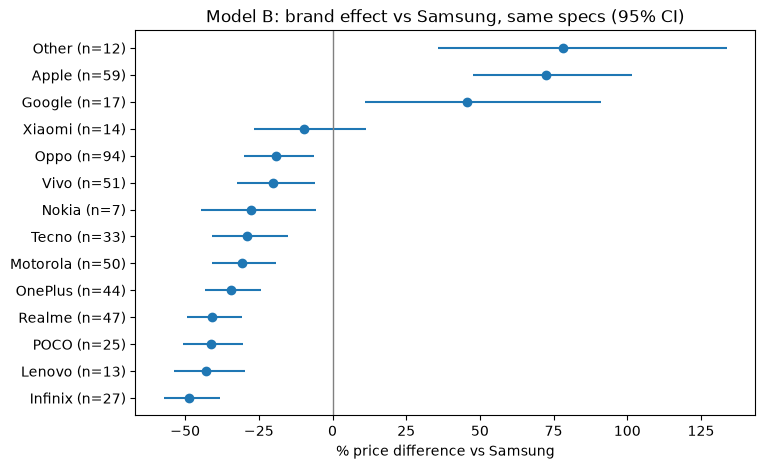

In [12]:
brand_rows = table_b[table_b.index.str.startswith("brand_")].sort_values("% price effect")
brands = brand_rows.index.str.removeprefix("brand_")
n_train = train["brand"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
pos = np.arange(len(brand_rows))
ax.errorbar(brand_rows["% price effect"], pos, fmt="o",
            xerr=[brand_rows["% price effect"] - brand_rows["95% CI low %"],
                  brand_rows["95% CI high %"] - brand_rows["% price effect"]])
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(pos, [f"{b} (n={n_train[b]})" for b in brands])
ax.set(title="Model B: brand effect vs Samsung, same specs (95% CI)", xlabel="% price difference vs Samsung")
plt.show()

**Takeaway (Model B, brand premiums vs Samsung, same specs):**
- Only three brands charge **more** than Samsung: **Apple +73 %** (95 % CI 48 % to 102 %), **Google +46 %** (11 % to 91 %) and **"Other" +78 %** (36 % to 134 %; Sony and Huawei flagships, only 12 training phones, hence the very wide interval).
- **Xiaomi** (−10 %) is the only brand whose interval includes 0: for the same specs, we cannot tell it apart from Samsung.
- All other brands are clearly cheaper for the same specs, from Oppo and Vivo (−19 %, −20 %) to Realme, POCO, Lenovo (about −41 to −43 %) and **Infinix −49 %**.
- Samsung is itself a premium-priced reference, so most brands appear "cheaper". Phase 8 re-expresses premiums relative to the **average** brand.

Adding brand also changes the spec and chip coefficients. Tensor drops from +75 % to 0 % and Kirin from +100 % to −20 % (not significant): in Model A those chips were mostly carrying the Google and Huawei brand effect. RAM rises to +48 % and storage falls to +10 % per doubling; section 5 explains why these two move around.

### Cross-validated comparison so far

In [13]:
pd.DataFrame({name: mean_pm_std(folds) for name, folds in results.items()}).T

,R²,median % error,MAE (₹)
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"
Model A: specs + chip,0.773 ± 0.039,23.3 ± 1.7,"14,273 ± 2,048"
Model B: specs + chip + brand,0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"


**Takeaway:** specs + chip lift R² from 0.37 (brand only) to **0.773**, and adding brand lifts it further to **0.845**, cutting the median price error from 23.3 % to **18.2 %**. So specs explain most of the price, and brand adds a clear, measurable extra. These numbers are higher than the pilot's (≈ 0.6 specs-only, ≈ 0.78 with brand) because our "specs-only" Model A already includes the chip group, which is very informative.

## 4. Diagnostics for Model B
OLS coefficients and their confidence intervals rely on some assumptions about the **residuals** (actual − predicted log price on the training data):
1. **Linearity:** no curved pattern in residuals vs fitted values.
2. **Constant variance** (*homoscedasticity*): the spread of residuals does not grow or shrink with the fitted value.
3. **Normality:** residuals roughly follow a bell curve. A **Q-Q plot** compares the sorted residuals with what a normal distribution would give; points on the straight line mean "normal".
4. **Independence:** one phone's error tells us nothing about another's. Storage variants of the same phone break this a little. That makes the confidence intervals somewhat too narrow, but it does not bias the coefficients.

/tmp/ipykernel_20662/293071121.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2].boxplot([resid[train["brand"] == b] for b in order], vert=False)


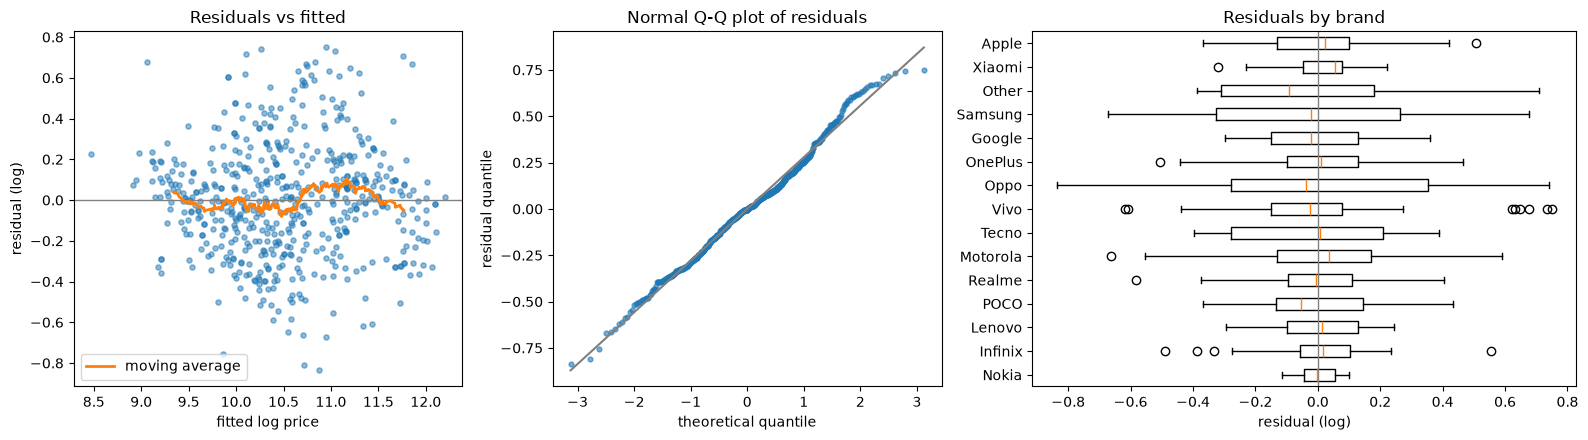

In [14]:
resid = y - fitted_b
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})

axes[0].scatter(fitted_b, resid, s=14, alpha=0.5)
axes[0].axhline(0, color="gray", linewidth=1)
smooth = pd.Series(resid.values, index=fitted_b.values).sort_index().rolling(60, center=True).mean()
axes[0].plot(smooth.index, smooth.values, color="tab:orange", linewidth=2, label="moving average")
axes[0].set(title="Residuals vs fitted", xlabel="fitted log price", ylabel="residual (log)")
axes[0].legend()

# Q-Q: the i-th smallest residual against where a normal distribution puts its i-th of n points, Φ⁻¹((i − 0.5)/n)
n = len(resid)
theoretical = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
axes[1].scatter(theoretical, np.sort(resid), s=12, alpha=0.6)
axes[1].plot(theoretical, resid.mean() + resid.std() * theoretical, color="gray")   # perfectly normal residuals
axes[1].set(title="Normal Q-Q plot of residuals", xlabel="theoretical quantile", ylabel="residual quantile")

order = train.groupby("brand")["log_price"].median().sort_values().index
axes[2].boxplot([resid[train["brand"] == b] for b in order], vert=False)
axes[2].set_yticks(range(1, len(order) + 1), order)
axes[2].axvline(0, color="gray", linewidth=1)
axes[2].set(title="Residuals by brand", xlabel="residual (log)")
fig.tight_layout()
plt.show()

In [15]:
print(f"residual std: {resid.std():.3f}  (a residual of 0.1 is about a 10 % price error)")
print(f"skewness: {stats.skew(resid):.2f}, excess kurtosis: {stats.kurtosis(resid):.2f}")
largest = train.assign(resid=resid).loc[resid.abs().sort_values(ascending=False).index[:6],
                                        ["brand", "Model Name", "price_inr", "resid"]]
print("\nLargest residuals:\n", largest.to_string())

residual std: 0.279  (a residual of 0.1 is about a 10 % price error)
skewness: 0.18, excess kurtosis: 0.15

Largest residuals:
     brand      Model Name  price_inr     resid
387  Oppo    K10 5G 256GB    22999.0 -0.835861
372  Oppo      K11x 256GB    20000.0 -0.811643
368  Oppo    A49 5G 128GB     8999.0 -0.753199
199  Vivo      X200 128GB   119999.0  0.748937
304  Oppo  K12 Plus 256GB    59999.0  0.742088
200  Vivo      X200 256GB   129999.0  0.733276


**Takeaway — do the linear assumptions look reasonable?** Mostly yes.
- **Linearity:** the moving average of the residuals stays within about ±0.1 of zero across the whole range, a slight wave but no strong curve.
- **Constant variance:** the vertical spread looks similar for cheap and expensive phones.
- **Normality:** the Q-Q points lie close to the line (skewness 0.18, excess kurtosis 0.15), with a slightly heavier upper tail (a few phones priced well above prediction).
- **By brand:** medians are near zero (brand dummies absorb each brand's average), but spreads differ. Samsung and Oppo have the widest spread because both sell everything from budget phones to foldables, and one brand premium cannot fit all their product lines. The largest misses are Oppo's K-series and A49 (about 55 % *below* prediction) and the Vivo X200 (about twice its predicted price). This hints at interactions (a brand's premium depending on the tier), which tree models can capture.
- **Independence** is mildly broken by storage variants, so the confidence intervals above are somewhat too narrow. Phase 8 uses a grouped bootstrap to get more honest intervals.

The residual standard deviation is 0.28 on the log scale, i.e. a typical in-sample error of roughly ±30 % in price.

## 5. Multicollinearity: condition number and VIF
When features are strongly correlated, many different combinations of coefficients fit the data almost equally well, so the individual coefficients become unstable.

**Condition number (as in lectures).** We **standardise** each feature (subtract its mean, divide by its standard deviation) so that units do not matter, form XᵀX, and compute its **eigenvalues** λ. Each eigenvalue measures how much the data varies along one direction (an eigenvector, i.e. a combination of features). A tiny eigenvalue means a combination of features that barely varies, so the data says almost nothing about the coefficients along that direction. Their variance is proportional to 1/λ. The condition number is λ_max / λ_min. Values in the tens are harmless, and values above about 100–1000 signal trouble. (Note: `numpy.linalg.cond(X)` gives the square root of this ratio.)

**VIF (variance inflation factor).** For feature *j*, regress it on all the other features and get R²ⱼ. Then VIF = 1 / (1 − R²ⱼ). It says how many times larger the variance of coefficient *j* is than it would be with uncorrelated features (its standard error is √VIF times larger). VIF ≈ 1 means no problem, and above about 5–10 is the usual warning level.

In [16]:
def eigen_report(X, label):
    Z = (X - X.mean()) / X.std(ddof=0)                  # standardise each column
    eigvals, eigvecs = np.linalg.eigh(Z.T @ Z)          # eigenvalues come out smallest first
    print(f"{label}: {Z.shape[1]} columns, λ_max = {eigvals.max():.1f}, λ_min = {eigvals.min():.2f}, "
          f"condition number λ_max/λ_min = {eigvals.max() / eigvals.min():.1f}")
    return eigvals, pd.DataFrame(eigvecs, index=X.columns)

# (a) the 9 numeric features alone
eig_num, vec_num = eigen_report(train[NUMERIC_FEATURES], "Numeric features")
# (b) Model B's full design matrix (numeric + chip dummies + brand dummies, no intercept)
eig_b, vec_b = eigen_report(X_b, "Model B design   ")

print("\nEigenvalues of the numeric-feature XᵀX (smallest first):", np.round(eig_num, 1))
print("\nThe eigenvector of the SMALLEST eigenvalue (numeric features), i.e. the least-determined direction:")
print(vec_num[0].round(2).sort_values(key=abs, ascending=False).to_string())
print("\nModel B design: largest loadings of its smallest-eigenvalue direction:")
print(vec_b[0].round(2).sort_values(key=abs, ascending=False).head(6).to_string())

Numeric features: 9 columns, λ_max = 2079.0, λ_min = 121.30, condition number λ_max/λ_min = 17.1
Model B design   : 31 columns, λ_max = 2373.3, λ_min = 25.05, condition number λ_max/λ_min = 94.7

Eigenvalues of the numeric-feature XᵀX (smallest first): [ 121.3  139.7  156.5  245.5  374.   412.3  656.5  837.2 2079. ]

The eigenvector of the SMALLEST eigenvalue (numeric features), i.e. the least-determined direction:
screen_in         0.53
weight_g         -0.49
log2_ram         -0.41
log2_storage      0.40
year             -0.31
battery_mah       0.14
main_back_mp      0.13
front_mp         -0.13
n_back_cameras    0.02

Model B design: largest loadings of its smallest-eigenvalue direction:
brand_Oppo        0.38
brand_Vivo        0.35
brand_Motorola    0.32
brand_Tecno       0.29
brand_Realme      0.28
brand_OnePlus     0.26


In [17]:
def vif(X, columns):
    out = {}
    for col in columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])   # R²ⱼ: feature j from all the others
        out[col] = 1 / (1 - r2)                                              # VIFⱼ = 1 / (1 − R²ⱼ)
    return pd.Series(out)

vif_table = pd.DataFrame({
    "VIF (numeric only)": vif(train[NUMERIC_FEATURES], NUMERIC_FEATURES),
    "VIF (in Model B, with chip + brand)": vif(X_b, NUMERIC_FEATURES),
}).round(2).sort_values("VIF (in Model B, with chip + brand)", ascending=False)
vif_table

,VIF (numeric only),"VIF (in Model B, with chip + brand)"
log2_ram,2.86,4.80
n_back_cameras,1.17,4.34
screen_in,2.88,4.26
weight_g,2.22,3.95
battery_mah,2.26,3.69
year,2.03,3.31
log2_storage,2.21,2.80
front_mp,1.69,2.76
main_back_mp,1.75,2.03


**Takeaway — collinearity is moderate, not severe, but it matters for RAM vs storage.**
- Numeric features alone: condition number **17** (eigenvalues from 121 to 2079), and all VIFs **below 3**. Inside Model B (with chip and brand dummies) the VIFs rise to at most **4.8** (RAM), still below the usual warning level of 5–10. RAM's standard error is about √4.8 ≈ 2.2 times what it would be with uncorrelated features.
- The **least-determined direction** (smallest eigenvalue) loads on screen vs weight (0.53 and 0.49, with opposite signs) and **RAM vs storage (0.41 and 0.40, with opposite signs)**. In words: "more RAM but less storage" and "heavier but smaller screen" are combinations the data barely contains, so it cannot say much about how price changes along them.
- That is exactly why the **split** between RAM and storage is unstable: Model A says RAM +27 % / storage +23 %, while Model B says RAM +48 % / storage +10 %. Their **combined** effect (doubling both) is much more stable: +56 % in A and +63 % in B. The same instability explains the screen coefficient flipping sign (−10 % in A, +10 % in B).
- Model B's full design matrix has condition number **95** after merging the Apple chip into the flagship group (before, it was effectively infinite: XᵀX was singular). Its weakest direction is all the brand dummies moving together, i.e. the overall level of non-Samsung brands relative to the intercept. Differences *between* brands are better determined than each brand's gap to Samsung.

Ridge regression (next notebook) is designed for exactly this situation: it shrinks the coefficients along these weakly determined directions.

## 6. Robustness: name-only data vs data with the 7 web-lookup phones
All of the above used the 558 training phones including the 3 web-lookup phones that fell into the training set. Here we repeat the cross-validation and the key coefficients on the name-only training data (555 phones).

In [18]:
compare = pd.concat({
    "with web lookup": pd.DataFrame({name: mean_pm_std(f) for name, f in results.items()}).T,
    "name-only": pd.DataFrame({name: mean_pm_std(f) for name, f in results_name.items()}).T,
}, axis=1)
compare

with web lookup                                      name-only                               
                                           R² median % error         MAE (₹)              R² median % error         MAE (₹)
Baseline 1: overall mean       -0.006 ± 0.005     59.1 ± 2.4  29,797 ± 2,812  -0.006 ± 0.005     59.2 ± 2.5  29,891 ± 2,825
Baseline 2: brand mean          0.366 ± 0.056     40.3 ± 3.1  22,181 ± 2,706   0.376 ± 0.055     39.7 ± 3.6  22,143 ± 2,744
Model A: specs + chip           0.773 ± 0.039     23.3 ± 1.7  14,273 ± 2,048   0.774 ± 0.037     23.4 ± 1.9  14,309 ± 1,993
Model B: specs + chip + brand   0.845 ± 0.018     18.2 ± 2.2  11,757 ± 1,658   0.846 ± 0.016     17.8 ± 2.0  11,750 ± 1,666

In [19]:
y_name = train_name["log_price"]
table_a_name = coef_table(fit_ols(design_matrix(train_name, ["chip_group"]), y_name))
table_b_name = coef_table(fit_ols(design_matrix(train_name), y_name))
key = ["log2_ram", "log2_storage", "brand_Infinix", "brand_Apple", "brand_Xiaomi"]
side_by_side = pd.DataFrame({
    "Model A % (with lookup)": table_a["% price effect"],
    "Model A % (name-only)": table_a_name["% price effect"],
    "Model B % (with lookup)": table_b["% price effect"],
    "Model B % (name-only)": table_b_name["% price effect"],
}).reindex(key).round(1)
side_by_side

,Model A % (with lookup),Model A % (name-only),Model B % (with lookup),Model B % (name-only)
log2_ram,27.1,26.9,48.4,49.6
log2_storage,22.5,22.3,10.0,9.3
brand_Infinix,NaN,NaN,-48.6,-48.5
brand_Apple,NaN,NaN,72.5,73.9
brand_Xiaomi,NaN,NaN,-9.5,-10.5


**Takeaway:** the 7 web-lookup phones make no practical difference. Cross-validated R² differs by only 0.001 for both Model A and Model B. The key coefficients move by at most 1.4 percentage points (Apple +72.5 % vs +73.9 %, RAM doubling +48.4 % vs +49.6 %), and the Infinix premium, the brand all 7 phones belong to, is unchanged (−48.6 % vs −48.5 %).

In [20]:
# Save mean and std of each metric per model; notebook 04 reads this file for its comparison table
rows = []
for name, folds in results.items():
    row = {"model": name}
    for metric, col in [("R²", "R2_log"), ("median % error", "median_pct_error"), ("MAE (₹)", "MAE_rupees")]:
        row[col + "_mean"] = folds[metric].mean()
        row[col + "_std"] = folds[metric].std()
    rows.append(row)
pd.DataFrame(rows).to_csv("../results/cv_phase4.csv", index=False)
print("Saved results/cv_phase4.csv")

Saved results/cv_phase4.csv


## Summary
| model | grouped CV R² | median % error |
|---|---|---|
| Baseline 1: overall mean | 0.00 | 59.1 % |
| Baseline 2: brand mean | 0.37 | 40.3 % |
| Model A: specs + chip | 0.773 | 23.3 % |
| Model B: specs + chip + brand | 0.845 | 18.2 % |

- Specs explain most of the price; brand adds a clear extra (R² +0.07, median error −5 points).
- With the same specs, Apple (+73 %), Google (+46 %) and the Sony/Huawei "Other" group (+78 %) charge more than Samsung. Infinix, Lenovo, POCO and Realme charge 40–50 % less.
- RAM and storage both matter, but how their joint effect is split between them is unstable (moderate collinearity). Camera megapixels do not matter once other specs are known.
- Decision made here: Apple A-series chips are grouped with flagship Snapdragon chips (`chip_group`), because otherwise the Apple brand and Apple chip columns are identical and the brand premium cannot be estimated.